## Data-Mining Practice 4
### Myrzakassymov Azizkhan 

### Part I. Model Evaluation and Hyperparameter Tuning
#### Tasks 1–4
#### Dataset requirements
Select a dataset suitable for a classification task from Kaggle, UCI Machine Learning
Repository, OpenML, or another reliable source.

Your dataset must:
- Contain at least 500 observations.
- Contain at least 5 input features.
- Have a categorical target variable with at least two classes.
- Be suitable for classification using scikit-learn.

Use the same dataset throughout Part I. Record its name, source, number of observations,
number of features, target variable, and class distribution.

#### Dataset
##### Adult

Donated on 4/30/1996

Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset.

##### Dataset Characteristics
Multivariate

##### Subject Area
Social Science

##### Associated Tasks
Classification

##### Feature Type
Categorical, Integer

##### Instances
48842

##### Features
14

##### Additional Information

Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the following conditions: ((AAGE>16) && (AGI>100) && (AFNLWGT>1)&& (HRSWK>0))

Prediction task is to determine whether a person's income is over $50,000 a year.

Dataset source: https://archive.ics.uci.edu/dataset/2/adult

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
train_test_split,
cross_val_score,
StratifiedKFold,
GridSearchCV,
RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
classification_report,
roc_auc_score
)


In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
adult = fetch_ucirepo(id=2) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(adult.data.features)
y = adult.data.targets 
  
display(X)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States


In [4]:
# Inspect the dataset
print(X.head())
print(X.shape)
print(X.info())
print(X.isnull().sum())

   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country  
0          2174             0              40  United-States  
1             0             0              13  United-St

Columns 'workclass', 'occupation' and 'native-country' have missing values.

I will impute them with 'Unknown', and also implement pipeline with KNN imputer for numerical data, in hypothetical case if someone will decide to train models on new data.

#### Task 1. Classification metrics and model comparison 
Train and evaluate Logistic Regression, Decision Tree, and k-NN classifiers. 

1. Calculate accuracy, precision, recall, F1-score, and ROC-AUC on the test set. 
2. Display the confusion matrix for each model. 
3. Compare the models using a table of performance metrics. 
4. Explain the difference between precision, recall, and F1-score. 
5. Select the most appropriate metric for your classification problem and justify your 
choice. 

Deliverable: Python code, a metric comparison table, confusion matrices, and a brief 
interpretation.

In [5]:
# Handle missing values and encode categorical variables
# as appropriate for your dataset.
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder

categorical = X.select_dtypes('object').columns.to_list()
numerical = X.select_dtypes('number').columns.to_list()

cat_pipeline = Pipeline( # Imputing and encoding categorical data
    [
        ('imputer', SimpleImputer(strategy='constant', fill_value='most_frequent')),
        ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
    ]
)
num_pipeline = Pipeline( # Imputing and encoding numerical data
    [
        ('imputer', KNNImputer()),
        ('scaler', StandardScaler())
    ]
)

preprocessor = ColumnTransformer( 
    transformers=[
        ('cat', cat_pipeline, categorical),
        ('num', num_pipeline, numerical)
    ]
)


In [6]:
# Split the data
from sklearn.utils import column_or_1d

y = y.squeeze()
y = y.str.rstrip('.')
y = (y == '>50K').astype(int)

# checking class balance
balance = len(y[y == 1])  / len(y)
print('Positive class (>50K) is ', balance, 'of whole dataset')

X_train, X_test, y_train, y_test = train_test_split(
X, column_or_1d(y),
test_size=0.2,
random_state=42,
stratify=y
)

Positive class (>50K) is  0.23928176569346055 of whole dataset


Positive target class is imbalanced, I will note this for the future.

In [7]:
# Classifying pipeline

classifiers = {
    'Logistic Regression' : LogisticRegression(n_jobs=-1),
    'Decision Tree' : DecisionTreeClassifier(),
    'K Nearest Neighbors' : KNeighborsClassifier(n_neighbors=10)
}
pipes = {}
performance_table = pd.DataFrame(
    columns=['Logistic Regression', 'Decision Tree', 'K Nearest Neighbors'],
    index=['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-score']
)


for classifier in classifiers:
    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifiers[classifier])
        ]
    )
    pipeline.fit(X_train, y_train)
    pipes[classifier] = pipeline

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1] 
    
    data = np.array(
        [accuracy_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)]
    )
    performance_table[classifier] = data

display(performance_table)

,Logistic Regression,Decision Tree,K Nearest Neighbors
Accuracy,0.851776,0.813185,0.843996
ROC-AUC,0.905911,0.746461,0.885617
Precision,0.732255,0.607818,0.725610
Recall,0.600086,0.618477,0.559880
F1-score,0.659614,0.613102,0.632062


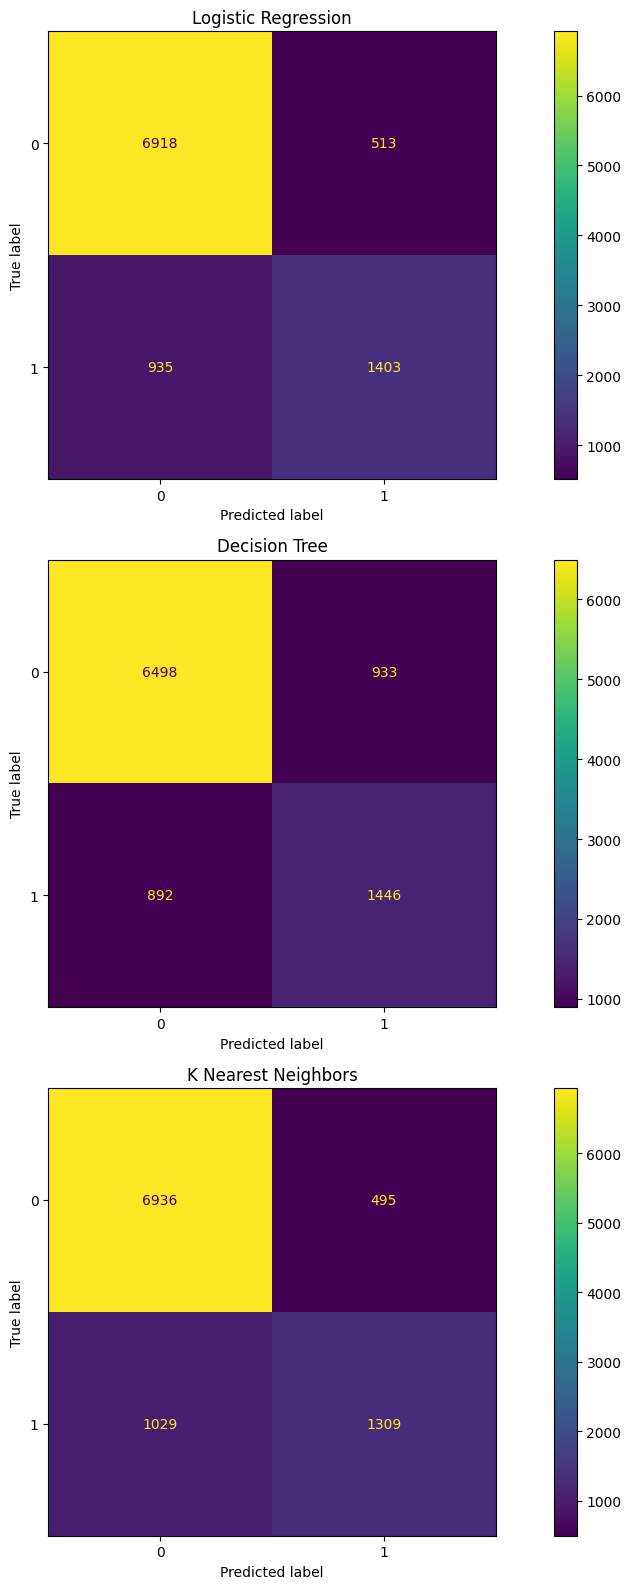

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize = (12, 16), dpi=100, nrows=3)

for i, pipe in enumerate(pipes):
    y_pred = pipes[pipe].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=ax[i]
    )
    ax[i].set_title(pipe)

plt.tight_layout()
plt.show()

Differences between Precision, Recall and F1-Score.

First of all, F1-score is dependent metric, that is born from Precision and Recall as their relations: 2 * Precision * Recall / (Precision + Recall).

Precision is a relation of True Positives and sum of True Positives and False Positives. Basically, if you don't need any false positives (Negatives, but called Positives by model), then you should increase Precision, by increasing threshold (of scoring or probability) for your model to identify observation as positive class.

Recall is a relation of True Positives and sum of True Positives and False Negatives, plays same role as Precision but for False Negatives (Positives, but called Negatives by model).

Both of metrics have a very stochastic function of model thresholds, so you have to tune them, watching on F1-score and PR curve.

In my task there's no specific need to identify if one will have >50k per year salary or not.

So, the most relevant metrics will be Accuracy and ROC-AUC.

#### Task 2. Overfitting and underfitting 
Investigate how model complexity affects generalization using a Decision Tree. 
1. Train models with max_depth values of 1, 2, 3, 5, 10, and None. 
2. Calculate training and testing accuracy for each configuration. 
3. Plot training and testing accuracy against tree depth. 
4. Identify configurations that show signs of underfitting or overfitting. 
5. Explain how limiting tree depth can improve generalization.
 
Deliverable: A results table, a line plot, and a written conclusion. 

In [9]:
depths = [1, 2, 3, 5, 10, None]
decision_tree_pipes = {}

for depth in depths:
    classifier = DecisionTreeClassifier(max_depth=depth)
    pipeline = Pipeline(
            steps=[
                ('preprocessor', preprocessor),
                ('classifier', classifier)
            ]
        )
    pipeline.fit(X_train, y_train)
    decision_tree_pipes[depth] = pipeline

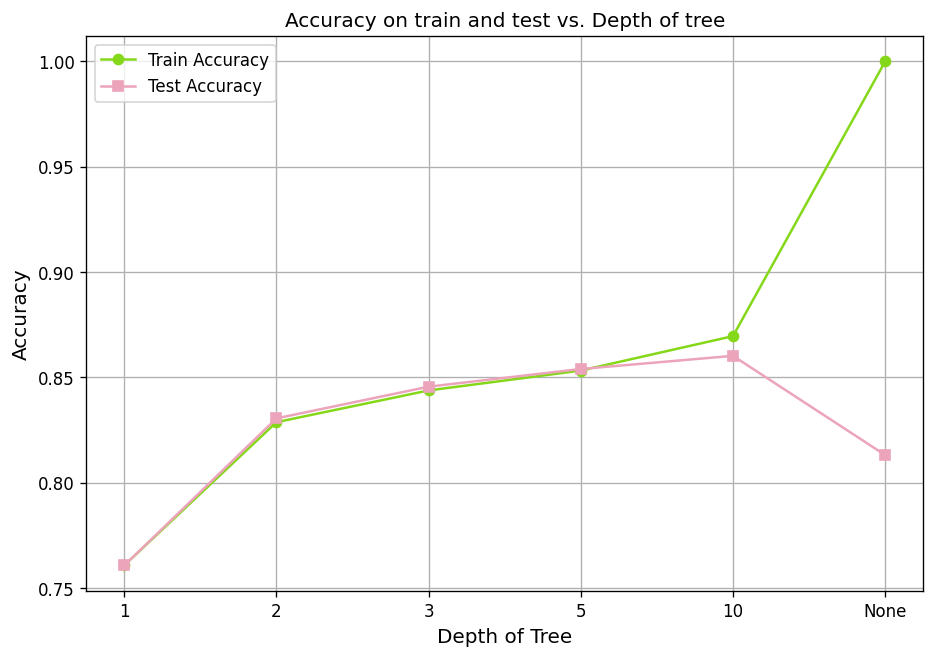

In [10]:
train_accuracies = []
test_accuracies = []
depths_str = [str(d) for d in depths]

for pipe in decision_tree_pipes:
    accuracy_train = accuracy_score(y_train, decision_tree_pipes[pipe].predict(X_train))
    accuracy_test = accuracy_score(y_test,  decision_tree_pipes[pipe].predict(X_test))

    train_accuracies.append(accuracy_train)
    test_accuracies.append(accuracy_test)
    
fig = plt.figure(figsize=(9, 6), dpi=120)
plt.plot(depths_str, train_accuracies, label='Train Accuracy', marker='o', color="#85D819")
plt.plot(depths_str, test_accuracies, label='Test Accuracy', marker='s', color="#ECA4BB")

plt.xlabel('Depth of Tree', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Accuracy on train and test vs. Depth of tree')
plt.legend(fontsize=10)
plt.grid(True)

plt.show()

In this plot we can observe how accuracy raises as depth of tree is raising, but when we don't limit our model in depth, it "memorize" training data, and trying to fit test data in very strict conditions. 
It is perfect in train data, but when it goes to unseen data, accuracy is very bad.

Underfitting comes from low variance and high bias of model. It would be the case if both of graphs had poor accuracy scalings. 
Overfitting comes from high variance and low bias of model. It means that model has a wide spread of predicting numbers, though in approximately correct average, like if we need five but model gave us 0 and 10 but for the same datapoint`, average is correct, but predictions are various. It results in bad accuracy in predicting testing data.

In this example our best depth would be somewhere between 5 and 10, because we can see that in depth of 10, accuracy on testing data is "outrunned" by training accuracy. May be slight overfitting. Too complex model tends to have a high variance in predicting.  

#### Task 3. K-fold cross-validation
Compare Logistic Regression, Decision Tree, and k-NN using five-fold stratified crossvalidation.
1. Use StratifiedKFold with n_splits=5 and shuffle=True.
2. Calculate the F1-score for each fold.
3. Calculate the mean and standard deviation of the five scores.
4. Compare the models in terms of performance and stability.
5. Explain why cross-validation is useful when evaluating machine learning models.


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True)

model_performance_means = {}
model_performance_stds = {}

for classifier in classifiers:
    f1_stratified = []
    pipeline = Pipeline( # pipeline 
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifiers[classifier])
        ]
    )

    for train_index, test_index in skf.split(X, y): # cross validation
        X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
        
        pipeline.fit(X_train_fold, y_train_fold) 
        y_pred_fold = pipeline.predict(X_test_fold) 
        f1_stratified.append(f1_score(y_test_fold, y_pred_fold))

    model_performance_means[classifier] = np.mean(f1_stratified) # mean and variance of cross-validation sample
    model_performance_stds[classifier] = np.std(f1_stratified)

In [23]:
print(list(model_performance_means.keys()))

['Logistic Regression', 'Decision Tree', 'K Nearest Neighbors']


In [30]:
table = pd.concat(
    [pd.DataFrame(model_performance_means.values(), index=list(model_performance_means.keys()), columns=['mean']),
    pd.DataFrame(model_performance_stds.values(), index=list(model_performance_stds.keys()), columns=['std'])],
    axis=1
)
display(table)

,mean,std
Logistic Regression,0.663187,0.003447
Decision Tree,0.619214,0.006759
K Nearest Neighbors,0.626562,0.009683


Logistic regression at average performs better than Decision Tree and KNN for this data.
F1 score is higher and more stable. 

Essentiality of cross validation for evaluating model's performance, as example can be seen here. The thing is, the output of model, accuracy, f1 and other metrics is as well are random variables that depends on sample data. It is statistically correct to use cross-validation, because it can show us distribution, mean and standard deviation of our model's metrics.

#### Task 4. Hyperparameter optimization
Optimize a classification model using both GridSearchCV and RandomizedSearchCV.
1. Select a model and define at least three hyperparameters to tune.
2. Apply five-fold cross-validation using F1-score as the selection metric.
3. Report the best hyperparameters and mean cross-validation score from each search.
4. Compare the search strategies in terms of search space, number of configurations
evaluated, and computational cost.
5. Evaluate the selected model on the test set and compare it with the default model.
6. Explain why the test set must not be used to select hyperparameters.

Possible hyperparameters include max_depth, min_samples_split, and min_samples_leaf for
Decision Trees, or n_neighbors, weights, and p for k-NN.

I will stop on Logistic Regression because it shows best results for my dataset.

In [1]:
param_grid = [
    {
        'penalty' : ['l1', 'l2', 'elasticnet', 'none'],
        'C': np.logspace(-4, 4, 20),
        'solver': ['lbfgs','newton-cg','liblinear','sag','saga', 'newton-cholesky'],
        'max_iter'  : [100,1000,2500,5000]
    }
]
log_model = LogisticRegression()

clf = GridSearchCV(log_model, param_grid=param_grid, cv=5, verbose=True, n_jobs=-1)

NameError: name 'np' is not defined

In [ ]:


for train_index, test_index in skf.split(X, y): # cross validation
        X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
        
        pipeline.fit(X_train_fold, y_train_fold) 
        y_pred_fold = pipeline.predict(X_test_fold) 
        f1_stratified.append(f1_score(y_test_fold, y_pred_fold))